# 02 · Subject-dependent 5-fold CV over 350 trials (shuffled vs blocked)

**Purpose.** Re-estimates subject-dependent accuracy using all 350 trials per subject with stratified 5-fold CV, in two schemes: shuffled (standard) and blocked/contiguous (leakage-safe). The per-subject difference is the leakage control.

**Produces.** Table 2 (shuffled and blocked means with 95% CIs) and Table 3 (per-subject shuffled, blocked, difference). Fig. 8 is drawn by `03_make_figures.ipynb`.

**Inputs.** `$RESULTS_DIR/paper/maps.pkl` written by `01` (else the maps are rebuilt from the BCIC2020 Track 3 `.mat` files).

**Outputs** (in `$RESULTS_DIR/kfold`): `maps350.pkl` (cache, not committed), `kfold_ckpt.csv`, `kfold_preds.pkl`, `per_subject_kfold.csv`, `leakage_control.csv`, `figure_sd_ci.png`.

**Run order.** After `01`. Checkpointed per (scheme, subject, fold) and resumable; needs several GPU hours on a T4, so it may span multiple Kaggle sessions. Use an empty `RESULTS_DIR` for a fresh run so the published `kfold_preds.pkl` is not overwritten.

# SD confidence interval — 5-fold CV over 350 trials + leakage control
Tightens the within-subject headline. Each subject is tested on **all 350 trials** across folds
(vs a single 50-trial split), giving stable per-subject estimates and a proper **95% CI on the mean**.

**Two schemes, reported side by side:**
- **A. Stratified shuffled 5-fold** — the standard within-subject CV protocol (comparable to prior CV work).
- **B. Stratified blocked 5-fold** (contiguous, no shuffle) — leakage-safe; guards the class-blocked
  subjects (S11, S12). If A ~ B, adjacency isn't leaking and the CV number is clean.

Also compares to the strict single **cross-file** split (49.7%) already reported. Locked config C0,
`WSTRIDE=3`, ~25K-param masked TD-CNN. Checkpointed per (scheme, subject, fold) — resumes across sessions.

In [1]:
import numpy as np, scipy.io, glob, os, time, gc, pickle
import pandas as pd
from scipy.interpolate import griddata
from scipy.spatial import cKDTree
from scipy import stats
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, f1_score, accuracy_score
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
for g in tf.config.list_physical_devices('GPU'): tf.config.experimental.set_memory_growth(g,True)
print('TF',tf.__version__,'| GPUs',len(tf.config.list_physical_devices('GPU')))

TF 2.20.0 | GPUs 2


In [2]:
# Config — LOCKED C0
NUM_CLASSES=5; FS=256; MAP=32; WSTRIDE=3; KFOLD=5
CFG=dict(l2=1e-4, sd=0.2, do=0.4)
label_to_channel={
    'Fp1':0,'Fp2':1,'F7':2,'F3':3,'Fz':4,'F4':5,'F8':6,'FC5':7,'FC1':8,'FC2':9,'FC6':10,
    'T7':11,'C3':12,'Cz':13,'C4':14,'T8':15,'TP9':16,'CP5':17,'CP1':18,'CP2':19,'CP6':20,
    'TP10':21,'P7':22,'P3':23,'Pz':24,'P4':25,'P8':26,'PO9':27,'O1':28,'Oz':29,'O2':30,
    'PO10':31,'AF7':32,'AF3':33,'AF4':34,'AF8':35,'F5':36,'F1':37,'F2':38,'F6':39,'FT9':40,
    'FT7':41,'FC3':42,'FC4':43,'FT8':44,'FT10':45,'C5':46,'C1':47,'C2':48,'C6':49,'TP7':50,
    'CP3':51,'CPz':52,'CP4':53,'TP8':54,'P5':55,'P1':56,'P2':57,'P6':58,'PO7':59,'PO3':60,
    'POz':61,'PO4':62,'PO8':63}
selected=list(label_to_channel.keys()); sel_idx=np.array([label_to_channel[c] for c in selected])
# Paths: BCIC_DATA / RESULTS_DIR environment variables override the Kaggle defaults;
# off Kaggle they fall back to ./data and ./results at the repository root.
_ROOT=os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd())=='notebooks' else os.getcwd()
ON_KAGGLE=os.path.exists('/kaggle/working')
RESULTS_DIR=os.environ.get('RESULTS_DIR') or ('/kaggle/working' if ON_KAGGLE else os.path.join(_ROOT,'results'))
DATA_ROOT=os.environ.get('BCIC_DATA')
if DATA_ROOT is None:
    for path in ['/kaggle/input/datasets/sanaephd/imu-shah-2024-dataset',
                 '/kaggle/input/imu-shah-2024-dataset','/kaggle/input/imu-shah-2024']+                ([f'/kaggle/input/{d}' for d in os.listdir('/kaggle/input')
                  if ('imu' in d.lower() or 'shah' in d.lower())] if os.path.exists('/kaggle/input') else [])+                [os.path.join(_ROOT,'data')]:
        if os.path.exists(os.path.join(path,'Train')) and os.path.exists(os.path.join(path,'valid')):
            DATA_ROOT=path; break
train_files=sorted(glob.glob(os.path.join(DATA_ROOT,'Train','*.mat')))
valid_files=sorted(glob.glob(os.path.join(DATA_ROOT,'valid','*.mat')))
OUT=os.path.join(RESULTS_DIR,'kfold'); os.makedirs(OUT,exist_ok=True)
CACHE=os.path.join(RESULTS_DIR,'paper','maps.pkl')      # reuse maps cache from paper_results if present
KCACHE=f'{OUT}/maps350.pkl'
CKPT=f'{OUT}/kfold_ckpt.csv'; PREDPK=f'{OUT}/kfold_preds.pkl'
print('dataset:',DATA_ROOT)

dataset: /kaggle/input/datasets/sanaephd/imu-shah-2024-dataset


In [3]:
# maps (reuse cache; else build). Keep all 350 trials per subject (train+valid concatenated).
def _todict(o):
    d={}
    for f in o._fieldnames:
        e=o.__dict__[f]; d[f]=_todict(e) if isinstance(e,scipy.io.matlab.mat_struct) else e
    return d
def _check(d):
    for k in d:
        if isinstance(d[k],scipy.io.matlab.mat_struct): d[k]=_todict(d[k])
    return d
mnt0=_check(scipy.io.loadmat(train_files[0],struct_as_record=False,squeeze_me=True))['mnt']
x_sel,y_sel=mnt0['x'][sel_idx],mnt0['y'][sel_idx]
xi,yi=np.meshgrid(np.linspace(x_sel.min(),x_sel.max(),MAP),np.linspace(y_sel.min(),y_sel.max(),MAP))
tree=cKDTree(np.c_[x_sel,y_sel]); d1,_=tree.query(np.c_[xi.ravel(),yi.ravel()],k=1)
dd,_=tree.query(np.c_[x_sel,y_sel],k=2); MASK=(d1.reshape(MAP,MAP)<=1.2*np.median(dd[:,1]))
def build_maps(file,win_ms=125,ov=50,start_map=6,end_map=44,wstride=WSTRIDE):
    md=_check(scipy.io.loadmat(file,struct_as_record=False,squeeze_me=True))
    epo=next(md[k] for k in ['epo_train','epo_test','epo_validation','epo'] if k in md)
    data=epo['x']; y=np.argmax(epo['y'],axis=0)
    win=round(FS*win_ms/1000); step=win-round(win*ov/100)
    total=data.shape[0]; n_maps=int(np.floor((total-round(win*ov/100))/step)); nt=data.shape[2]
    filt=data.copy()
    for t in range(nt):
        tr=filt[:,:,t]; filt[:,:,t]=tr-tr.mean(axis=1,keepdims=True)
    wins=[w for w in range(n_maps) if (start_map-1<=w<end_map) and ((w-(start_map-1))%wstride==0)]
    out=np.zeros((nt,len(wins),MAP,MAP,1),dtype=np.float32)
    for t in range(nt):
        dt=filt[:,sel_idx,t]
        for wi,w in enumerate(wins):
            s=w*step; e=s+win; v=dt[s:e,:].mean(0)
            zi=np.where(MASK,griddata((x_sel,y_sel),v,(xi,yi),method='cubic'),np.nan)
            lo,hi=np.nanmin(zi),np.nanmax(zi); zn=(zi-lo)/(hi-lo) if hi>lo else np.zeros_like(zi)
            out[t,wi,:,:,0]=np.nan_to_num(np.clip(zn,0,1))
    return out,y

if os.path.exists(KCACHE):
    with open(KCACHE,'rb') as f: subj=pickle.load(f); print('loaded 350-trial maps cache')
elif os.path.exists(CACHE):
    with open(CACHE,'rb') as f: base=pickle.load(f)
    subj=[dict(id=s['id'],name=s['name'],
               X=np.concatenate([s['Xtr'],s['Xte']]),y=np.concatenate([s['ytr'],s['yte']])) for s in base]
    with open(KCACHE,'wb') as f: pickle.dump(subj,f); print('assembled 350-trial maps from paper cache')
else:
    t0=time.time(); subj=[]
    for i,(tf_,vf_) in enumerate(zip(train_files,valid_files)):
        Xa,ya=build_maps(tf_); Xb,yb=build_maps(vf_)
        subj.append(dict(id=i,name=os.path.basename(tf_).replace('.mat',''),
                         X=np.concatenate([Xa,Xb]),y=np.concatenate([ya,yb])))
        print(f'[{i+1:2d}/15] built 350')
    with open(KCACHE,'wb') as f: pickle.dump(subj,f); print(f'built+cached in {time.time()-t0:.0f}s')
INP=subj[0]['X'].shape[1:]; print('input',INP,'| trials/subject',subj[0]['X'].shape[0])

/tmp/ipykernel_55901/520700553.py:9: DeprecationWarning: Please import `mat_struct` from the `scipy.io.matlab` namespace; the `scipy.io.matlab.mio5_params` namespace is deprecated and will be removed in SciPy 2.0.0.
  if isinstance(d[k],scipy.io.matlab.mio5_params.mat_struct): d[k]=_todict(d[k])
/tmp/ipykernel_55901/520700553.py:5: DeprecationWarning: Please import `mat_struct` from the `scipy.io.matlab` namespace; the `scipy.io.matlab.mio5_params` namespace is deprecated and will be removed in SciPy 2.0.0.
  e=o.__dict__[f]; d[f]=_todict(e) if isinstance(e,scipy.io.matlab.mio5_params.mat_struct) else e


loaded 350-trial maps cache
input (13, 32, 32, 1) | trials/subject 350


In [4]:
# model (C0) + fold splitters + fit
def build_model(input_shape=INP,n_classes=NUM_CLASSES,w1=32,w2=64,wb=16,l2=CFG['l2'],sd=CFG['sd'],do=CFG['do'],lr=1e-3):
    reg=regularizers.l2(l2); inp=layers.Input(shape=input_shape)
    x=layers.TimeDistributed(layers.Conv2D(w1,3,padding='same',activation='relu',kernel_regularizer=reg))(inp)
    x=layers.TimeDistributed(layers.BatchNormalization())(x)
    x=layers.TimeDistributed(layers.MaxPooling2D(2))(x)
    x=layers.TimeDistributed(layers.SpatialDropout2D(sd))(x)
    x=layers.TimeDistributed(layers.Conv2D(w2,3,padding='same',activation='relu',kernel_regularizer=reg))(x)
    x=layers.TimeDistributed(layers.BatchNormalization())(x)
    x=layers.TimeDistributed(layers.MaxPooling2D(2))(x)
    x=layers.TimeDistributed(layers.SpatialDropout2D(sd))(x)
    x=layers.TimeDistributed(layers.Conv2D(wb,1,padding='same',activation='relu',kernel_regularizer=reg))(x)
    x=layers.TimeDistributed(layers.Flatten())(x)
    x=layers.GlobalAveragePooling1D()(x)
    x=layers.Dropout(do)(x)
    out=layers.Dense(n_classes,activation='softmax',kernel_regularizer=reg)(x)
    m=models.Model(inp,out); m.compile(optimizer=optimizers.Adam(lr),loss='categorical_crossentropy',metrics=['accuracy'])
    return m

def strat_shuffled_folds(y,k=KFOLD,seed=0):
    rng=np.random.RandomState(seed); folds=[[] for _ in range(k)]
    for c in range(NUM_CLASSES):
        idx=np.where(y==c)[0]; rng.shuffle(idx)
        for i,ix in enumerate(idx): folds[i%k].append(int(ix))
    return [np.array(sorted(f)) for f in folds]

def strat_blocked_folds(y, k=KFOLD, seed=0):   # seed ignored (blocked = deterministic), kept for uniform call signature
    folds=[[] for _ in range(k)]
    for c in range(NUM_CLASSES):
        idx=np.where(y==c)[0]
        for i,s in enumerate(np.array_split(idx,k)): folds[i].extend(s.tolist())
    return [np.array(sorted(f)) for f in folds]
def inner_val(y_tr_idx, y, seed=0):
    rng=np.random.RandomState(seed); tr=[]; va=[]
    for c in range(NUM_CLASSES):
        ci=y_tr_idx[y[y_tr_idx]==c]; rng.shuffle(ci); k=max(1,int(len(ci)*0.15)); va+=list(ci[:k]); tr+=list(ci[k:])
    return np.array(tr),np.array(va)

def fit_fold(X,y,tr_idx,seed=0,epochs=70,batch=32):
    tr,va=inner_val(tr_idx,y,seed); m=build_model()
    m.fit(X[tr],to_categorical(y[tr],NUM_CLASSES),
          validation_data=(X[va],to_categorical(y[va],NUM_CLASSES)),
          epochs=epochs,batch_size=batch,verbose=0,
          callbacks=[EarlyStopping('val_loss',patience=12,restore_best_weights=True,verbose=0),
                     ReduceLROnPlateau('val_loss',factor=0.5,patience=5,min_lr=1e-6,verbose=0)])
    return m
print('params:',f'{build_model().count_params():,}')

I0000 00:00:1784153773.360703   55901 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1784153773.366841   55901 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


params: 25,365


## Run 5-fold CV — schemes A (shuffled) and B (blocked), checkpointed

In [5]:
# resume state
if os.path.exists(CKPT):
    ck=pd.read_csv(CKPT); done=set(zip(ck.scheme,ck.subject_id,ck.fold)); print(f'resuming — {len(ck)} folds done')
else:
    ck=pd.DataFrame(); done=set(); print('starting fresh')
if os.path.exists(PREDPK):
    with open(PREDPK,'rb') as f: PRED=pickle.load(f)
else:
    PRED={'shuffled':{}, 'blocked':{}}   # PRED[scheme][sid] = length-350 y_pred (filled per fold)

SCHEMES={'shuffled':strat_shuffled_folds, 'blocked':strat_blocked_folds}
rows=[]; t0=time.time()
for scheme,foldfn in SCHEMES.items():
    for s in subj:
        sid=s['id']; y=s['y']; X=s['X']
        PRED[scheme].setdefault(sid, -np.ones(len(y),dtype=int))
        folds=foldfn(y, seed=sid)   # seed varies fold assignment per subject (shuffled only)
        for fi,test_idx in enumerate(folds):
            if (scheme,sid,fi) in done: continue
            tr_idx=np.setdiff1d(np.arange(len(y)),test_idx)
            m=fit_fold(X,y,tr_idx,seed=1000*fi+sid)
            yp=np.argmax(m.predict(X[test_idx],verbose=0),axis=1)
            PRED[scheme][sid][test_idx]=yp
            acc=accuracy_score(y[test_idx],yp)
            rows.append(dict(scheme=scheme,subject_id=sid,subject=s['name'],fold=fi,
                             test_acc=acc*100,n_test=len(test_idx)))
            # checkpoint every fold
            ck=pd.concat([ck,pd.DataFrame([rows[-1]])],ignore_index=True); ck.to_csv(CKPT,index=False)
            with open(PREDPK,'wb') as f: pickle.dump(PRED,f)
            done.add((scheme,sid,fi))
            del m; keras.backend.clear_session(); gc.collect()
        acc_s=accuracy_score(y, PRED[scheme][sid]) if (PRED[scheme][sid]>=0).all() else np.nan
        print(f"{scheme:9s} {s['name']}: {acc_s*100:.1f}% (350-trial CV)  [{time.time()-t0:.0f}s]")
print(f'\nall folds complete in {(time.time()-t0)/60:.1f} min')

resuming — 134 folds done
shuffled  Data_Sample01: 50.0% (350-trial CV)  [0s]
shuffled  Data_Sample02: 41.4% (350-trial CV)  [0s]
shuffled  Data_Sample03: 44.6% (350-trial CV)  [0s]
shuffled  Data_Sample04: 42.9% (350-trial CV)  [0s]
shuffled  Data_Sample05: 60.6% (350-trial CV)  [0s]
shuffled  Data_Sample06: 28.6% (350-trial CV)  [0s]
shuffled  Data_Sample07: 54.3% (350-trial CV)  [0s]
shuffled  Data_Sample08: 43.4% (350-trial CV)  [0s]
shuffled  Data_Sample09: 40.6% (350-trial CV)  [0s]
shuffled  Data_Sample10: 38.9% (350-trial CV)  [0s]
shuffled  Data_Sample11: 39.7% (350-trial CV)  [0s]
shuffled  Data_Sample12: 61.4% (350-trial CV)  [0s]
shuffled  Data_Sample13: 41.7% (350-trial CV)  [0s]
shuffled  Data_Sample14: 42.3% (350-trial CV)  [0s]
shuffled  Data_Sample15: 46.3% (350-trial CV)  [0s]
blocked   Data_Sample01: 52.0% (350-trial CV)  [0s]
blocked   Data_Sample02: 42.9% (350-trial CV)  [0s]
blocked   Data_Sample03: 46.6% (350-trial CV)  [0s]
blocked   Data_Sample04: 46.6% (350-tr

I0000 00:00:1784153821.314257   55950 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


blocked   Data_Sample12: 36.9% (350-trial CV)  [109s]
blocked   Data_Sample13: 34.0% (350-trial CV)  [608s]
blocked   Data_Sample14: 49.4% (350-trial CV)  [1121s]
blocked   Data_Sample15: 55.1% (350-trial CV)  [1658s]

all folds complete in 27.6 min


## Aggregate — per-subject (all 350) + 95% CI on the mean

In [6]:
def M(yt,yp): return dict(bal_acc=balanced_accuracy_score(yt,yp)*100,
                          kappa=cohen_kappa_score(yt,yp), wf1=f1_score(yt,yp,average='weighted')*100)
psr=[]
for scheme in ['shuffled','blocked']:
    for s in subj:
        yp=PRED[scheme][s['id']]
        if (yp<0).any(): continue
        mm=M(s['y'],yp); mm.update(scheme=scheme,subject=s['name'],sid=s['id']); psr.append(mm)
P=pd.DataFrame(psr)

def ci95(v):
    v=np.asarray(v); m=v.mean(); se=v.std(ddof=1)/np.sqrt(len(v)); h=stats.t.ppf(0.975,len(v)-1)*se
    bs=np.array([np.random.RandomState(k).choice(v,len(v),replace=True).mean() for k in range(10000)])
    return m, m-h, m+h, np.percentile(bs,2.5), np.percentile(bs,97.5)

print('SD via 5-fold CV over 350 trials (mean over 15 subjects):')
for scheme in ['shuffled','blocked']:
    sub=P[P.scheme==scheme]
    if len(sub)<15: print(f'  {scheme}: incomplete ({len(sub)}/15)'); continue
    m,tl,th,bl,bh=ci95(sub.bal_acc)
    print(f'  {scheme:9s} Bal.Acc {m:5.2f}%  std {sub.bal_acc.std():4.2f}  '
          f'95%CI t[{tl:.1f},{th:.1f}] boot[{bl:.1f},{bh:.1f}] | '
          f'kappa {sub.kappa.mean():.3f} | W-F1 {sub.wf1.mean():.2f}')
# leakage control: shuffled - blocked, per subject
if P.scheme.nunique()==2 and (P.groupby('scheme').size()>=15).all():
    piv=P.pivot_table(index='subject',columns='scheme',values='bal_acc')
    piv['A_minus_B']=piv['shuffled']-piv['blocked']
    print(f"\nLeakage control (shuffled - blocked): mean {piv.A_minus_B.mean():+.1f}pp")
    print('  large positive on S11/S12 would flag block-adjacency leakage:')
    print(piv.round(1).to_string())
    P.to_csv(f'{OUT}/per_subject_kfold.csv'); piv.to_csv(f'{OUT}/leakage_control.csv')

SD via 5-fold CV over 350 trials (mean over 15 subjects):
  shuffled  Bal.Acc 45.10%  std 8.53  95%CI t[40.4,49.8] boot[41.1,49.4] | kappa 0.314 | W-F1 44.89
  blocked   Bal.Acc 43.01%  std 8.41  95%CI t[38.4,47.7] boot[38.8,47.0] | kappa 0.288 | W-F1 42.86

Leakage control (shuffled - blocked): mean +2.1pp
  large positive on S11/S12 would flag block-adjacency leakage:
scheme         blocked  shuffled  A_minus_B
subject                                    
Data_Sample01     52.0      50.0       -2.0
Data_Sample02     42.9      41.4       -1.4
Data_Sample03     46.6      44.6       -2.0
Data_Sample04     46.6      42.9       -3.7
Data_Sample05     47.7      60.6       12.9
Data_Sample06     24.9      28.6        3.7
Data_Sample07     52.6      54.3        1.7
Data_Sample08     45.1      43.4       -1.7
Data_Sample09     39.7      40.6        0.9
Data_Sample10     38.6      38.9        0.3
Data_Sample11     33.1      39.7        6.6
Data_Sample12     36.9      61.4       24.6
Data_Sample

## Figure + comparison to the single cross-file split

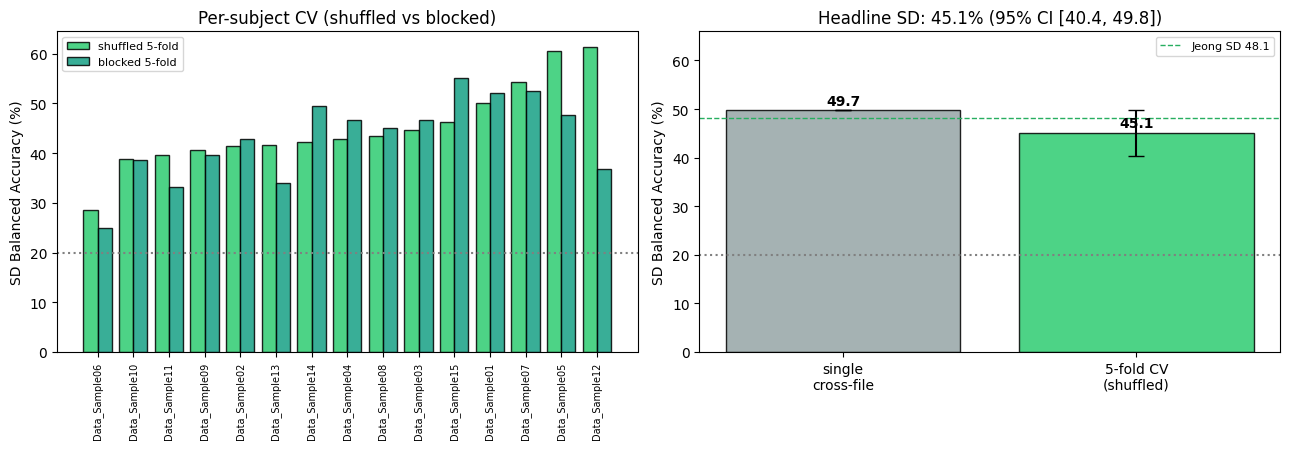

saved /kaggle/working/kfold/figure_sd_ci.png


In [7]:
SINGLE_CROSSFILE=49.73   # from paper_results (single train->valid split)
if (P.scheme.nunique()==2) and (P.groupby('scheme').size()>=15).all():
    sh=P[P.scheme=='shuffled'].sort_values('bal_acc'); bl=P[P.scheme=='blocked'].set_index('subject')
    fig,ax=plt.subplots(1,2,figsize=(13,4.6))
    x=np.arange(15); w=0.4
    ax[0].bar(x-w/2,sh.bal_acc,w,label='shuffled 5-fold',color='#2ecc71',alpha=.85,edgecolor='k')
    ax[0].bar(x+w/2,[bl.loc[s,'bal_acc'] for s in sh.subject],w,label='blocked 5-fold',color='#16a085',alpha=.85,edgecolor='k')
    ax[0].axhline(20,ls=':',c='gray'); ax[0].set_xticks(x); ax[0].set_xticklabels(sh.subject,rotation=90,fontsize=7)
    ax[0].set_ylabel('SD Balanced Accuracy (%)'); ax[0].set_title('Per-subject CV (shuffled vs blocked)'); ax[0].legend(fontsize=8)
    m,tl,th,bl2,bh2=ci95(sh.bal_acc)
    ax[1].bar(['single\ncross-file','5-fold CV\n(shuffled)'],[SINGLE_CROSSFILE,m],
              yerr=[[0,m-tl],[0,th-m]],capsize=6,color=['#95a5a6','#2ecc71'],alpha=.85,edgecolor='k')
    ax[1].axhline(20,ls=':',c='gray'); ax[1].axhline(48.1,ls='--',c='#27ae60',lw=1,label='Jeong SD 48.1')
    ax[1].set_ylabel('SD Balanced Accuracy (%)'); ax[1].set_ylim(0,66)
    ax[1].set_title(f'Headline SD: {m:.1f}% (95% CI [{tl:.1f}, {th:.1f}])'); ax[1].legend(fontsize=8)
    for i,v in enumerate([SINGLE_CROSSFILE,m]): ax[1].text(i,v+1.2,f'{v:.1f}',ha='center',fontweight='bold')
    plt.tight_layout(); plt.savefig(f'{OUT}/figure_sd_ci.png',dpi=200,bbox_inches='tight'); plt.show()
    print('saved',f'{OUT}/figure_sd_ci.png')
else:
    print('run both schemes to completion for the figure')

## Reads
- **Headline:** the paper reports the **blocked** 5-fold estimate, **43.0%** (95% CI [38.4, 47.7]), as the conservative within-subject figure; the shuffled estimate (45.1%, [40.4, 49.8]) is shown alongside it.
- **Leakage control:** **S12 (+24.6 pp)** is the only clear leakage outlier (shuffled minus blocked); the mean gap over subjects is +2.1 pp.
- **Stability:** the between-subject std fell from **14.3** (single 50-trial cross-session split) to **8.5** with 350-trial CV. The CI on the mean is what this notebook tightens.